# Laboratorio #2: Limpieza y transformación de datos
## Grupo 3 · Carnet P000021441
### *SINF-633 Análisis Exploratorio de Datos · Universidad Cenfotec*

### *Caso:* Comercial del Pacífico S.A. El Gerente Comercial dice que los datos "se ven sucios" y que los totales de los reportes no cuadran. Se limpian dos archivos: ventas_productos.csv y empleados_rrhh.csv.

### *Orden del proceso* (cada paso prepara al siguiente):
#### 1. Diagnóstico → 2. Texto → 3. Anomalías → 4. Duplicados → 5. Imputación → 6. Escalado → 7. Variables nuevas → 8. Pipeline → 9. Verificación

#### Los duplicados y las anomalías se tratan *antes de imputar, para que no cuenten doble ni contaminen la mediana. El escalado va **después de imputar*, porque los NaN lo dañan.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 40)

# Ruta de los datos: ../data/ si existe, si no la carpeta del notebook
RUTA = "../data/" if Path("../data/ventas_productos.csv").exists() else ""

# Copias originales (nunca se modifican) y copias de trabajo
df_raw = pd.read_csv(RUTA + "ventas_productos.csv")
df_emp_raw = pd.read_csv(RUTA + "empleados_rrhh.csv")
df = df_raw.copy()
df_emp = df_emp_raw.copy()

print("Ventas:", df.shape, "| Empleados:", df_emp.shape)



Ventas: (1530, 7) | Empleados: (600, 10)


## 1. Diagnóstico inicial
Antes de cambiar nada se mide el problema: nulos, duplicados, texto inconsistente y valores imposibles, con una tabla resumen y un mapa de calor.

In [2]:
# Tabla resumen por columna
for nombre, d in [("VENTAS", df_raw), ("EMPLEADOS", df_emp_raw)]:
    print(f"===== {nombre}: {d.shape[0]} filas x {d.shape[1]} columnas =====")
    resumen = pd.DataFrame({
        "tipo": d.dtypes.astype(str),
        "nulos": d.isna().sum(),
        "% nulos": (d.isna().mean() * 100).round(2),
        "únicos": d.nunique(),
    })
    display(resumen)
    print("Duplicados absolutos:", d.duplicated().sum(), "\n")

# Problemas específicos de ventas
print("id_venta repetidos:", df_raw["id_venta"].duplicated().sum())
print("Precios negativos:", (df_raw["precio_unitario"] < 0).sum())
print("Cantidades <= 0:", (df_raw["cantidad"] <= 0).sum())
print("Región (variantes):", sorted(df_raw["region"].dropna().unique()))
print("Vendedor (variantes):", sorted(df_raw["vendedor"].dropna().unique()))
print("Tipo de fecha_venta:", df_raw["fecha_venta"].dtype)
print("Empleados con valores negativos:", (df_emp_raw.select_dtypes("number") < 0).sum().sum())

===== VENTAS: 1530 filas x 7 columnas =====


,tipo,nulos,% nulos,únicos
id_venta,int64,0,0.00,1500
producto,object,47,3.07,200
cantidad,float64,29,1.90,57
precio_unitario,float64,36,2.35,1455
fecha_venta,object,0,0.00,354
vendedor,object,41,2.68,9
region,object,26,1.70,9


Duplicados absolutos: 30 

===== EMPLEADOS: 600 filas x 10 columnas =====


,tipo,nulos,% nulos,únicos
id_empleado,int64,0,0.00,600
departamento,object,0,0.00,6
cargo,object,0,0.00,5
salario_mensual,float64,28,4.67,572
antiguedad_anos,float64,0,0.00,137
edad,float64,20,3.33,36
satisfaccion_laboral,float64,32,5.33,87
horas_extra_mes,float64,0,0.00,37
ausencias_mes,int64,0,0.00,8
renuncio,int64,0,0.00,2


Duplicados absolutos: 0 

id_venta repetidos: 30
Precios negativos: 10
Cantidades <= 0: 15
Región (variantes): ['Centro', 'Este', 'NORTE', 'Norte', 'Oeste', 'SUR', 'Sur', 'norte', 'sur']
Vendedor (variantes): ['Ana López', 'CARLOS RUIZ', 'Carlos Ruiz', 'Diego Castro', 'Laura Torres', 'María González', 'Pedro Jiménez', 'ana lópez', 'maria gonzalez']
Tipo de fecha_venta: object
Empleados con valores negativos: 0


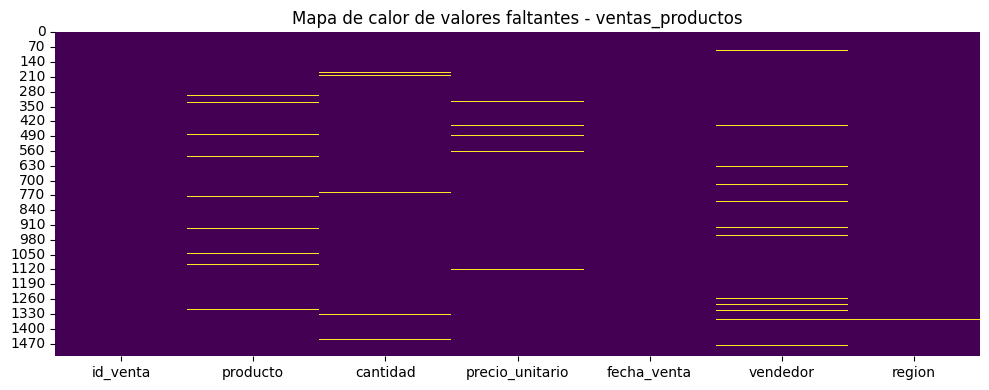

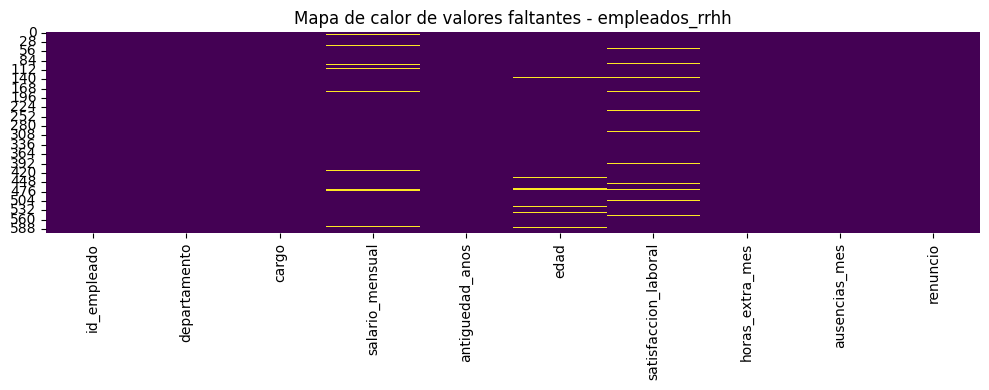

In [3]:
# 6) Mapa de calor de ventas
plt.figure(figsize=(10,4))
sns.heatmap(df.isna(), cbar=False, cmap='viridis')
plt.title('Mapa de calor de valores faltantes - ventas_productos')
plt.tight_layout()
plt.savefig('mapa_calor_nulos.png', dpi=120)
plt.show()

# 7) Mapa de calor de empleados (gráfico aparte)
plt.figure(figsize=(10,4))
sns.heatmap(df_emp.isna(), cbar=False, cmap='viridis')
plt.title('Mapa de calor de valores faltantes - empleados_rrhh')
plt.tight_layout()
plt.savefig('mapa_calor_nulos_empleados.png', dpi=120)
plt.show()


*Resultado del diagnóstico*

| | Ventas (1 530 × 7) | Empleados (600 × 10) |
|---|---|---|
| Nulos | 179 celdas: producto 47, vendedor 41, precio 36, cantidad 29, región 26 | 80 celdas: salario 28, edad 20, satisfacción 32 |
| Duplicados absolutos | *30* (y 30 id_venta repetidos) | 0 |
| Valores imposibles | *10 precios negativos* y *15 cantidades ≤ 0* | 0 |
| Texto inconsistente | region con 9 variantes (son 5) y vendedor con 9 (son 6) | Sin problemas |
| Fecha | Llegó como texto | — |

- Las *15 cantidades ≤ 0* no las menciona el enunciado; salieron del diagnóstico.
- *Mapa de calor de ventas:* los nulos (marcas amarillas) están repartidos sueltos en producto, cantidad, precio_unitario, vendedor y region; id_venta y fecha_venta no tienen nulos.
- *Mapa de calor de empleados:* los nulos aparecen solo en salario_mensual, edad y satisfaccion_laboral, también dispersos.
- En ninguno de los dos hay columnas ni filas dañadas por completo.
- Esto explica por qué los totales no cuadran: los duplicados inflan las ventas, las regiones escritas distinto se cuentan por separado, y los precios negativos restan dinero.

## 2. Limpieza de texto
*Criterio:* str.strip() quita espacios al inicio y al final, y str.title() unifica mayúsculas ("SUR", "sur" → "Sur"). Después se revisa qué inconsistencias quedan. Los códigos de producto van en mayúscula con str.upper().

In [4]:
# Paso 1: strip + title
df["vendedor"] = df["vendedor"].str.strip().str.title()
df["region"] = df["region"].str.strip().str.title()
print("Vendedores tras strip + title:", sorted(df["vendedor"].dropna().unique()))

# Paso 2: "María González" y "Maria Gonzalez" siguen separados -> se quitan las tildes
def quitar_tildes(serie):
    return serie.str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("ascii")

df["vendedor"] = quitar_tildes(df["vendedor"])
df["region"] = quitar_tildes(df["region"])

# Códigos de producto y texto de empleados
df["producto"] = df["producto"].str.strip().str.upper()
for col in ["departamento", "cargo"]:
    df_emp[col] = df_emp[col].str.strip().str.title()

# La fecha llegó como texto -> datetime
df["fecha_venta"] = pd.to_datetime(df["fecha_venta"], errors="coerce")

print("\nVendedores finales:", sorted(df["vendedor"].dropna().unique()))
print("Regiones finales:", sorted(df["region"].dropna().unique()))
print("Fecha:", df["fecha_venta"].dtype, "| inválidas:", df["fecha_venta"].isna().sum(),
      "| rango:", df["fecha_venta"].min().date(), "->", df["fecha_venta"].max().date())

Vendedores tras strip + title: ['Ana López', 'Carlos Ruiz', 'Diego Castro', 'Laura Torres', 'Maria Gonzalez', 'María González', 'Pedro Jiménez']

Vendedores finales: ['Ana Lopez', 'Carlos Ruiz', 'Diego Castro', 'Laura Torres', 'Maria Gonzalez', 'Pedro Jimenez']
Regiones finales: ['Centro', 'Este', 'Norte', 'Oeste', 'Sur']
Fecha: datetime64[ns] | inválidas: 0 | rango: 2023-01-01 -> 2023-12-31


*Resultado de la limpieza de texto*
- region pasó de 9 a *5* variantes (Centro, Este, Norte, Oeste, Sur) solo con strip + title.
- vendedor pasó de 9 a *7, pero quedaron "María González" y "Maria Gonzalez" como personas distintas, porque title no unifica las tildes. Con el segundo paso (quitar tildes) quedaron **6 vendedores*.
- Los nombres quedan sin tilde ("Maria Gonzalez"): se prefirió la *consistencia* para agrupar bien.
- La fecha ahora es datetime64, sin fechas inválidas, y cubre todo 2023.

## 3. Anomalías numéricas
Un precio negativo es imposible. Se revisa dónde ocurre y se decide qué hacer con esos registros.

*Decisión: convertirlos en NaN, no eliminar la fila.* La venta sí ocurrió (tiene producto, fecha, región y vendedor); solo el valor es inválido. Eliminarla alteraría los totales por vendedor y región. Se hace *antes de imputar* para que el valor negativo no contamine la media ni la mediana. Lo mismo se aplica a las cantidades menores o iguales a cero.

In [5]:
# ¿Dónde están los precios negativos?
negativos = df[df["precio_unitario"] < 0]
display(negativos)
print("Por vendedor:", negativos["vendedor"].value_counts().to_dict())
print("Por región:", negativos["region"].value_counts().to_dict())

# Convertir a NaN (se imputarán después)
df.loc[df["precio_unitario"] < 0, "precio_unitario"] = np.nan
df.loc[df["cantidad"] <= 0, "cantidad"] = np.nan

print("\nNulos ahora -> cantidad:", df["cantidad"].isna().sum(), "| precio:", df["precio_unitario"].isna().sum())
display(df[["cantidad", "precio_unitario"]].describe().T)

# Empleados: ¿hay valores imposibles?
print("Empleados -> salario <= 0:", (df_emp["salario_mensual"] <= 0).sum(),
      "| edad fuera de 18-70:", ((df_emp["edad"] < 18) | (df_emp["edad"] > 70)).sum(),
      "| satisfacción fuera de 1-10:", ((df_emp["satisfaccion_laboral"] < 1) | (df_emp["satisfaccion_laboral"] > 10)).sum())

,id_venta,producto,cantidad,precio_unitario,fecha_venta,vendedor,region
137,138,PROD-0080,3.00,-68.27,2023-03-09,Ana Lopez,Oeste
290,291,PROD-0063,45.00,-93.17,2023-09-06,Laura Torres,Norte
384,385,PROD-0053,8.00,-11.71,2023-01-22,Carlos Ruiz,Sur
569,570,PROD-0042,39.00,-91.47,2023-02-23,Diego Castro,Norte
686,687,PROD-0164,9.00,-22.44,2023-09-20,Carlos Ruiz,Este
868,869,PROD-0168,44.00,-95.57,2023-07-31,Maria Gonzalez,Centro
1098,1099,PROD-0166,24.00,-34.60,2023-12-25,Diego Castro,Centro
1199,1200,PROD-0020,34.00,-16.18,2023-12-18,Diego Castro,Centro
1390,1391,PROD-0006,49.00,-58.17,2023-01-09,Maria Gonzalez,Oeste
1426,1427,PROD-0024,28.00,-45.26,2023-11-08,Ana Lopez,Este


Por vendedor: {'Diego Castro': 3, 'Ana Lopez': 2, 'Carlos Ruiz': 2, 'Maria Gonzalez': 2, 'Laura Torres': 1}
Por región: {'Centro': 3, 'Oeste': 2, 'Norte': 2, 'Este': 2, 'Sur': 1}

Nulos ahora -> cantidad: 44 | precio: 46


,count,mean,std,min,25%,50%,75%,max
cantidad,"1,486.00",25.59,14.06,1.00,13.00,26.00,38.00,49.00
precio_unitario,"1,484.00",770.02,425.50,6.28,409.52,786.74,"1,127.90","1,498.42"


Empleados -> salario <= 0: 0 | edad fuera de 18-70: 0 | satisfacción fuera de 1-10: 0


*Resultado de las anomalías*
- Los 10 precios negativos están repartidos entre los 5 vendedores y las 5 regiones: no se concentran en ninguno, así que no apuntan a una sola fuente del error.
- Después de convertirlos en NaN, los nulos pasaron a *46 en precio* (36 + 10) y *44 en cantidad* (29 + 15). Ahora el precio mínimo es 6,28 y la cantidad mínima es 1: los rangos son lógicos.
- No se eliminó ninguna fila: las ventas se conservan y se imputarán más adelante.
- *Empleados:* 0 valores imposibles (salario, edad y satisfacción dentro de rango).
- *Salvedad:* una cantidad negativa podría ser una devolución. El archivo no tiene una columna que lo indique, así que se trató como error de captura. Conviene confirmarlo con Sistemas.

## 4. Eliminación de duplicados
- *Duplicado absoluto:* todas las columnas iguales (la misma venta cargada dos veces). Se elimina.
- *Duplicado por clave parcial:* mismo id_venta, o misma combinación de campos, con otros datos distintos. Hay que revisar cuál versión es la correcta

Primero se *inspeccionan* (keep=False muestra todas las copias) y luego se elimina conservando la *primera* aparición.

In [6]:
# --- Ventas ---
print("Duplicados absolutos:", df.duplicated().sum())
display(df[df.duplicated(keep=False)].sort_values("id_venta").head(6))

print("id_venta repetidos:", df["id_venta"].duplicated().sum())
clave = ["producto", "cantidad", "precio_unitario", "fecha_venta", "vendedor", "region"]
print("Repetidos por combinación de campos (sin el id):", df.duplicated(subset=clave).sum())

filas_antes = len(df)
df = df.drop_duplicates(ignore_index=True)          # conserva la primera aparición
print(f"\nVentas: {filas_antes} -> {len(df)} filas | id_venta único: {df['id_venta'].is_unique}")

# --- Empleados ---
print("\nEmpleados -> duplicados absolutos:", df_emp.duplicated().sum(),
      "| id_empleado repetidos:", df_emp["id_empleado"].duplicated().sum())

Duplicados absolutos: 30


,id_venta,producto,cantidad,precio_unitario,fecha_venta,vendedor,region
7,8,PROD-0131,16.00,99.52,2023-05-27,Carlos Ruiz,Sur
1505,8,PROD-0131,16.00,99.52,2023-05-27,Carlos Ruiz,Sur
1525,18,PROD-0054,13.00,"1,313.99",2023-11-27,Laura Torres,Sur
17,18,PROD-0054,13.00,"1,313.99",2023-11-27,Laura Torres,Sur
31,32,PROD-0091,28.00,967.24,2023-04-08,Pedro Jimenez,Norte
1500,32,PROD-0091,28.00,967.24,2023-04-08,Pedro Jimenez,Norte


id_venta repetidos: 30
Repetidos por combinación de campos (sin el id): 30

Ventas: 1530 -> 1500 filas | id_venta único: True

Empleados -> duplicados absolutos: 0 | id_empleado repetidos: 0


*Resultado de los duplicados*
- Había *30 duplicados absolutos*. La inspección muestra pares idénticos (por ejemplo, los id_venta 8, 18 y 32 aparecen dos veces con los mismos datos).
- Los 30 id_venta repetidos y las 30 repeticiones por combinación de campos son *las mismas 30 filas. Es decir, **no hay duplicados parciales con datos distintos*: no hay conflicto sobre cuál versión conservar.
- Criterio: se conserva la *primera* aparición. Resultado: *1 530 → 1 500 filas*, y id_venta queda único.
- *Empleados:* 0 duplicados absolutos y 0 id_empleado repetidos; no se elimina nada.
- Por qué importa: con los duplicados, las ventas totales estaban infladas en esas 30 transacciones.

## 5. Imputación diferenciada
Regla del enunciado: *numéricas con la mediana* y *categóricas con la moda o un valor sentinela. Además hay que **comparar al menos dos estrategias* y justificar la elegida. Se comparan media, mediana y KNN mirando cuánto cambian la media y la desviación estándar (std).

### 5.1 Ventas

In [7]:
cols = ["cantidad", "precio_unitario"]
print("Nulos antes:", df[cols].isna().sum().to_dict())

# Tres versiones del dataset, una por estrategia
df_media = df.copy()
df_media[cols] = df[cols].fillna(df[cols].mean())

df_mediana = df.copy()
df_mediana[cols] = df[cols].fillna(df[cols].median())

df_knn = df.copy()
df_knn[cols] = KNNImputer(n_neighbors=5, weights="distance").fit_transform(df[cols])

# Comparativa: media y std de cada método
comparativa = pd.DataFrame({
    "Original": df[cols].agg(["mean", "std"]).T.stack(),
    "Media":    df_media[cols].agg(["mean", "std"]).T.stack(),
    "Mediana":  df_mediana[cols].agg(["mean", "std"]).T.stack(),
    "KNN":      df_knn[cols].agg(["mean", "std"]).T.stack(),
})
display(comparativa)
print("Asimetría (skew):", df[cols].skew().round(2).to_dict())
print("Media vs mediana del precio:", round(df["precio_unitario"].mean(), 2), "vs", df["precio_unitario"].median())

# Imputación elegida: MEDIANA
df[cols] = df[cols].fillna(df[cols].median())
df["cantidad"] = df["cantidad"].round().astype(int)       # las unidades son enteros

# Categóricas: valor sentinela (la moda le asignaría ventas a un vendedor o producto sin evidencia)
print("\nModa de vendedor:", df["vendedor"].mode()[0], "-> recibiría", df["vendedor"].isna().sum(), "ventas que no son suyas")
df["producto"] = df["producto"].fillna("PROD-DESCONOCIDO")
df["vendedor"] = df["vendedor"].fillna("No reportado")
df["region"] = df["region"].fillna("Sin región")

print("Nulos totales en ventas:", df.isna().sum().sum())

Nulos antes: {'cantidad': 44, 'precio_unitario': 45}


Original  Media  Mediana    KNN
cantidad        mean     25.59  25.59    25.60  25.54
                std      14.10  13.89    13.89  13.99
precio_unitario mean    770.99 770.99   771.48 773.04
                std     424.25 417.83   417.84 419.01

Asimetría (skew): {'cantidad': -0.06, 'precio_unitario': -0.07}
Media vs mediana del precio: 770.99 vs 787.17

Moda de vendedor: Carlos Ruiz -> recibiría 41 ventas que no son suyas
Nulos totales en ventas: 0


*Resultado de la imputación en ventas*

| Variable | Original | Media | Mediana | KNN |
|---|---|---|---|---|
| cantidad (media / std) | 25,59 / 14,10 | 25,59 / 13,89 | 25,60 / 13,89 | 25,54 / 13,99 |
| precio_unitario (media / std) | 770,99 / 424,25 | 770,99 / 417,83 | 771,48 / 417,84 | 771,10 / 419,01 |

- *Media:* la media no cambia, pero la desviación baja (en precio, 424,25 → 417,83): los valores imputados quedan pegados al centro.
- *Mediana:* casi igual a la media; la media sube apenas 0,49 en precio.
- *KNN:* conserva un poco mejor la desviación (419,01), pero usa más cálculo y la diferencia es mínima.
- Las tres estrategias dan resultados muy parecidos porque cantidad y precio son casi *simétricas* (asimetría de −0,06 y −0,07) y tienen pocos nulos. La media del precio (770,99) y la mediana (787,17) están cerca.
- *Decisión: mediana.* Es la regla del enunciado, es robusta si llegaran valores extremos en datos futuros y es la más simple. No se eligió porque haya outliers en estos datos.
- *Categóricas con sentinela, no con moda:* con la moda, Carlos Ruiz recibiría 41 ventas que no son suyas. Con No reportado, PROD-DESCONOCIDO y Sin región el dato faltante queda visible y se puede filtrar.
- *Resultado final:* 0 nulos en ventas.



### 5.2 Empleados
Se agrega la *mediana por cargo* porque el salario depende del cargo. En KNN las variables se *estandarizan* antes, porque KNN usa distancias y el salario (miles) dominaría sobre la edad (decenas).

In [8]:
cols_nulos = ["salario_mensual", "edad", "satisfaccion_laboral"]
cols_num = ["salario_mensual", "antiguedad_anos", "edad", "satisfaccion_laboral", "horas_extra_mes", "ausencias_mes"]
print("Nulos antes:", df_emp[cols_nulos].isna().sum().to_dict())
print("\nSalario mediano por cargo:")
print(df_emp.groupby("cargo")["salario_mensual"].median().round(0).to_dict())

# Estrategias
e_media = df_emp[cols_nulos].fillna(df_emp[cols_nulos].mean())
e_mediana = df_emp[cols_nulos].fillna(df_emp[cols_nulos].median())

e_cargo = df_emp[cols_nulos].copy()
e_cargo["salario_mensual"] = e_cargo["salario_mensual"].fillna(df_emp.groupby("cargo")["salario_mensual"].transform("median"))
e_cargo = e_cargo.fillna(e_cargo.median())

esc = StandardScaler()
datos = KNNImputer(n_neighbors=5, weights="distance").fit_transform(esc.fit_transform(df_emp[cols_num]))
e_knn = pd.DataFrame(esc.inverse_transform(datos), columns=cols_num)[cols_nulos]

comparativa_emp = pd.DataFrame({
    "Original":          df_emp[cols_nulos].agg(["mean", "std"]).T.stack(),
    "Media":             e_media.agg(["mean", "std"]).T.stack(),
    "Mediana":           e_mediana.agg(["mean", "std"]).T.stack(),
    "Mediana por cargo": e_cargo.agg(["mean", "std"]).T.stack(),
    "KNN":               e_knn.agg(["mean", "std"]).T.stack(),
})
display(comparativa_emp)

# La media y la std no dicen qué tan cerca queda cada valor imputado del real.
# Prueba: se ocultan 15 % de los salarios que SÍ conocemos, se imputan y se mide el error promedio (menor = mejor)
rng = np.random.default_rng(42)
conocidos = df_emp.index[df_emp["salario_mensual"].notna()]
ocultos = rng.choice(conocidos, size=int(len(conocidos) * 0.15), replace=False)
real = df_emp.loc[ocultos, "salario_mensual"]

prueba = df_emp.copy()
prueba.loc[ocultos, "salario_mensual"] = np.nan

esc2 = StandardScaler()
datos2 = KNNImputer(n_neighbors=5, weights="distance").fit_transform(esc2.fit_transform(prueba[cols_num]))
predicciones = {
    "Media": pd.Series(prueba["salario_mensual"].mean(), index=ocultos),
    "Mediana": pd.Series(prueba["salario_mensual"].median(), index=ocultos),
    "Mediana por cargo": prueba.groupby("cargo")["salario_mensual"].transform("median")[ocultos],
    "KNN": pd.Series(esc2.inverse_transform(datos2)[:, 0], index=prueba.index)[ocultos],   # salario es la 1ª columna
}
error = pd.Series({nombre: (pred - real).abs().mean() for nombre, pred in predicciones.items()}, name="error promedio en salario")
display(error.round(0).to_frame())

# Imputación elegida: salario -> mediana por cargo | edad y satisfacción -> mediana
df_emp["salario_mensual"] = df_emp["salario_mensual"].fillna(df_emp.groupby("cargo")["salario_mensual"].transform("median"))
df_emp["edad"] = df_emp["edad"].fillna(df_emp["edad"].median())
df_emp["satisfaccion_laboral"] = df_emp["satisfaccion_laboral"].fillna(df_emp["satisfaccion_laboral"].median())

# departamento y cargo no tenían nulos; si los tuvieran se usaría la moda
print("\nNulos totales en empleados:", df_emp.isna().sum().sum())

Nulos antes: {'salario_mensual': 28, 'edad': 20, 'satisfaccion_laboral': 32}

Salario mediano por cargo:
{'Analista': 1258.0, 'Coordinador': 2661.0, 'Director': 8617.0, 'Especialista': 1876.0, 'Gerente': 4258.0}


Original    Media  Mediana  Mediana por cargo  \
salario_mensual      mean  2,170.38 2,170.38 2,154.87           2,188.25   
                     std   1,268.19 1,238.19 1,240.18           1,304.94   
edad                 mean     31.10    31.10    31.06              31.06   
                     std       7.17     7.05     7.05               7.05   
satisfaccion_laboral mean      5.26     5.26     5.26               5.26   
                     std       2.09     2.03     2.03               2.03   

                               KNN  
salario_mensual      mean 2,172.25  
                     std  1,243.52  
edad                 mean    31.16  
                     std      7.23  
satisfaccion_laboral mean     5.27  
                     std      2.04

,error promedio en salario
Media,868.00
Mediana,800.00
Mediana por cargo,199.00
KNN,"1,014.00"



Nulos totales en empleados: 0


*Resultado de la imputación en empleados*

Comparación de estadísticos (salario):

| Método | Media | Std |
|---|---|---|
| Original | 2 170,38 | 1 268,19 |
| Media | 2 170,38 | 1 238,19 |
| Mediana | 2 154,87 | 1 240,18 |
| Mediana por cargo | 2 188,25 | 1 304,94 |
| KNN | 2 172,25 | 1 243,52 |

Todas dejan la media casi igual y cambian la desviación en menos de 3 %, así que *este cuadro no alcanza para elegir*: no mide qué tan cerca queda cada valor imputado del real. Por eso se hizo la prueba del error.

Prueba del error (se ocultó el 15 % de los salarios conocidos y se imputaron):

| Estrategia | Error promedio en salario |
|---|---|
| Media | 868 |
| Mediana | 800 |
| *Mediana por cargo* | *199* |
| KNN | 1 014 |

- La mediana por cargo reduce el error a *menos de la cuarta parte*. Tiene sentido: el salario mediano va de 1 258 (Analista) a 8 617 (Director), y rellenar a un director con la mediana de todos (≈ 1 838) sería un error enorme.
- KNN conserva bien la desviación, pero es la peor para acertar el salario: *conservar la desviación no es lo mismo que acertar el valor*.
- La media pierde frente a las otras en esta prueba, que era lo que pedía el enunciado comparar (media vs. KNN).
- *Decisión:* salario con la mediana de su cargo; edad y satisfacción con la mediana. Departamento y cargo no tenían nulos.
- *Resultado final:* 0 nulos en empleados.
- *Limitación:* la prueba del error se hizo solo para el salario. En edad y satisfacción se usó la mediana por la regla del enunciado, sin medir si otro método acierta más.

## 6. Escalado
Las variables están en escalas muy distintas (salario en miles, edad en decenas). Se aplican los tres escaladores del enunciado a las columnas numéricas de empleados:

| Escalador | Qué hace | Sensible a outliers |
|---|---|---|
| MinMaxScaler | Lleva los datos al rango [0, 1] | Mucho |
| StandardScaler | Media 0 y desviación 1 | Sí |
| RobustScaler | Usa mediana e IQR | No |

MinMax                Standard                  Robust  \
                        min  max mean  50%      min  max  mean   50%    min   
salario_mensual        0.00 1.00 0.14 0.10    -0.90 5.62 -0.00 -0.25  -0.72   
antiguedad_anos        0.00 1.00 0.16 0.11    -0.96 5.01  0.00 -0.29  -0.66   
edad                   0.00 1.00 0.21 0.19    -1.29 4.81  0.00 -0.15  -1.00   
satisfaccion_laboral   0.00 1.00 0.47 0.48    -2.10 2.33  0.00  0.02  -1.64   
horas_extra_mes        0.00 1.00 0.22 0.19    -1.42 4.96 -0.00 -0.23  -1.14   
ausencias_mes          0.00 1.00 0.30 0.29    -1.44 3.40  0.00 -0.06  -1.00   

                                      
                      max  mean  50%  
salario_mensual      6.62  0.29 0.00  
antiguedad_anos      5.25  0.29 0.00  
edad                 4.38  0.13 0.00  
satisfaccion_laboral 1.79 -0.01 0.00  
horas_extra_mes      5.00  0.22 0.00  
ausencias_mes        2.50  0.04 0.00

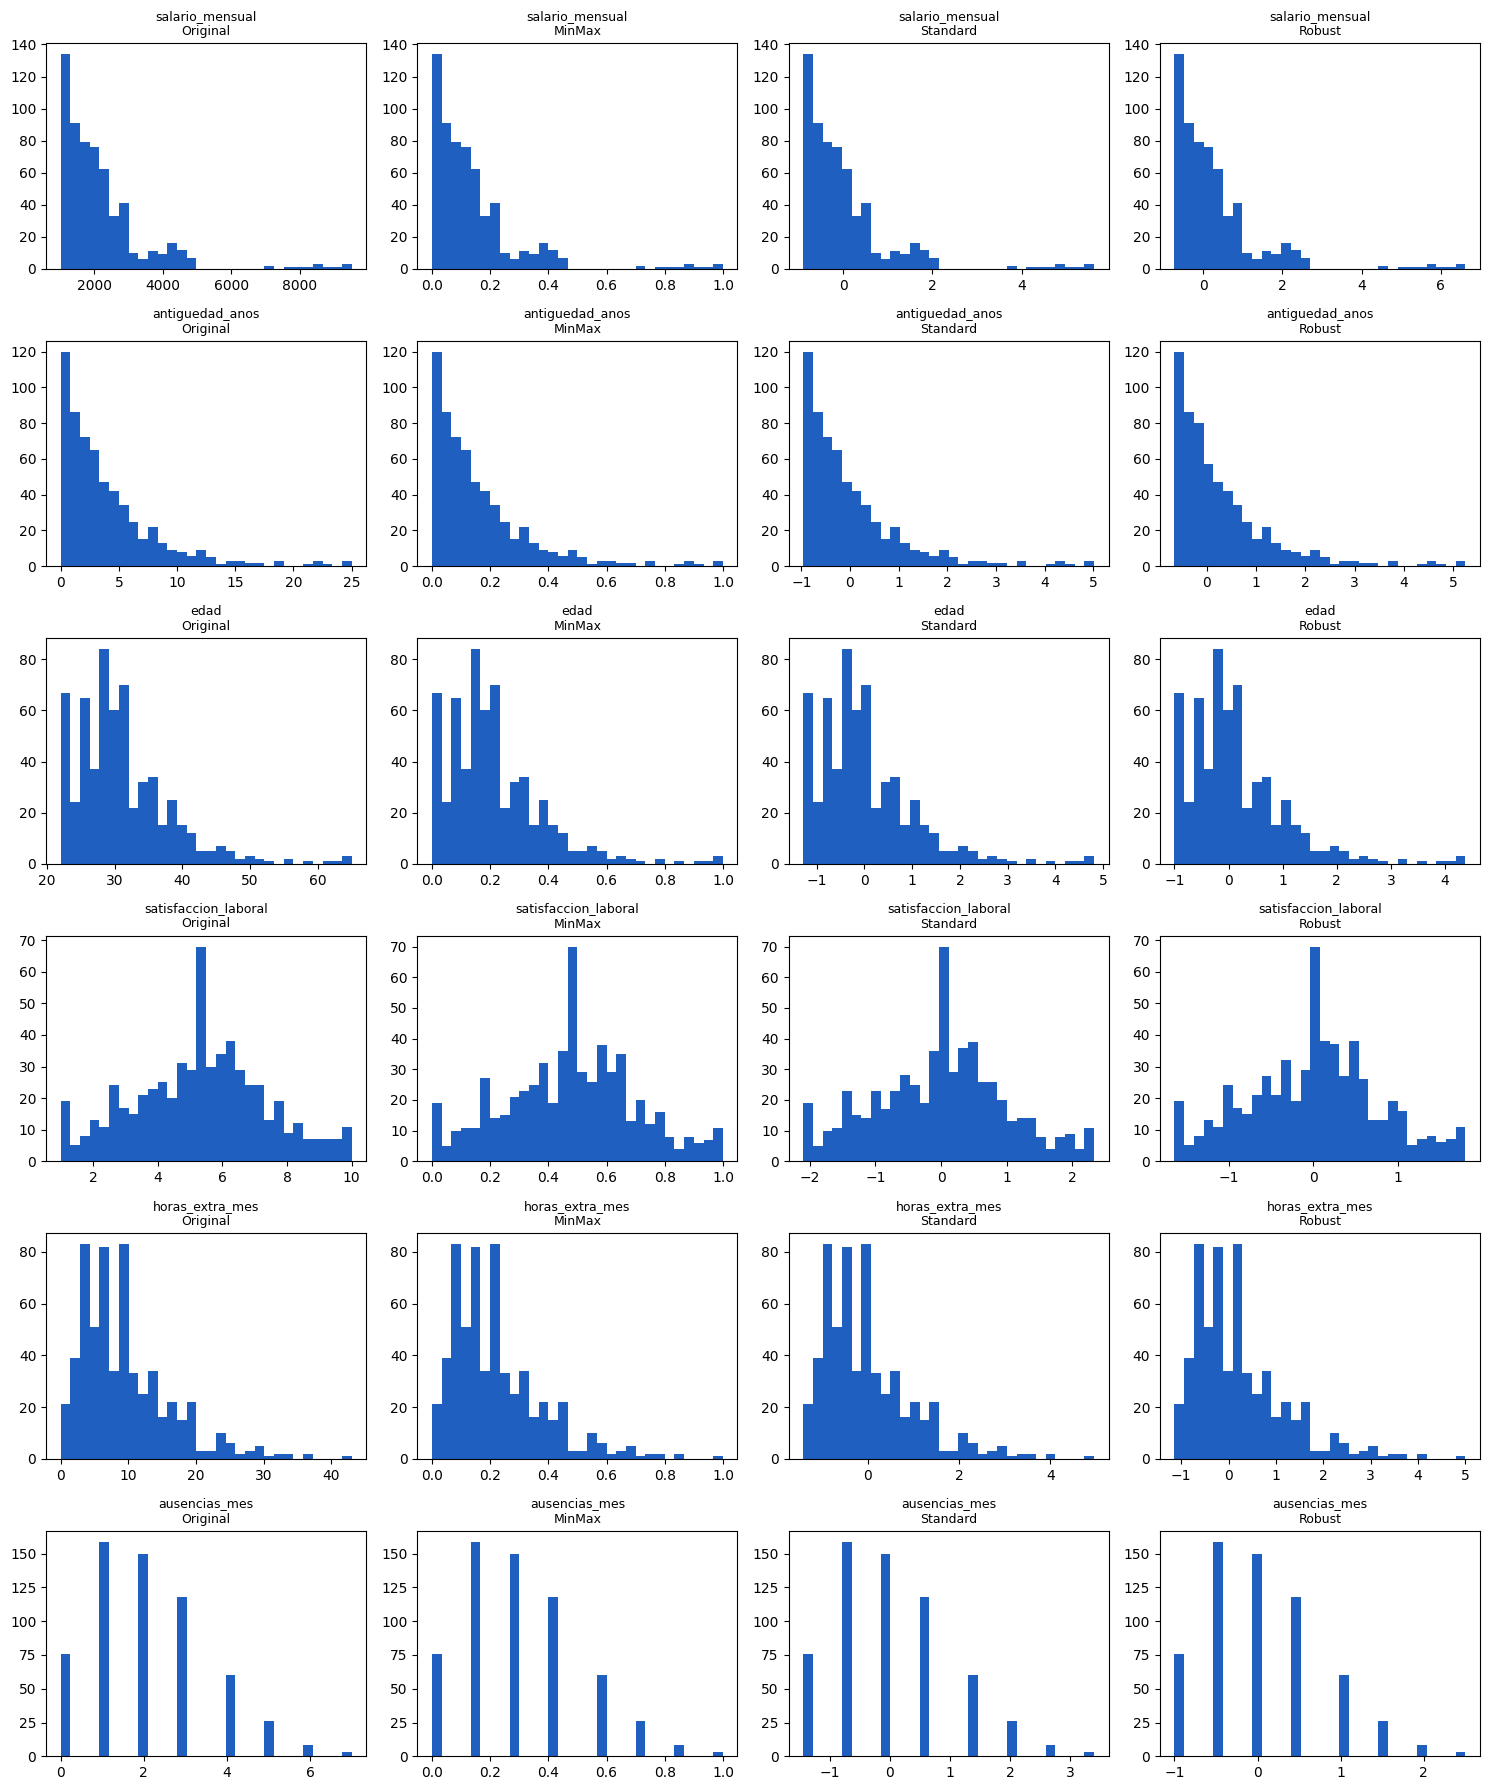

,skew,% outliers,escalador elegido
salario_mensual,2.83,7.50,Robust
antiguedad_anos,2.11,5.83,Robust
edad,1.54,3.50,Robust
satisfaccion_laboral,0.02,0.00,Standard
horas_extra_mes,1.36,5.67,Robust
ausencias_mes,0.61,0.50,Standard


In [9]:
# ## 6. Escalado
# Las variables están en escalas muy distintas (salario en miles, edad en decenas). Se aplican los tres escaladores del enunciado a las columnas numéricas de empleados:
#
# | Escalador | Qué hace | Sensible a outliers |
# |---|---|---|
# | MinMaxScaler | Lleva los datos al rango [0, 1] | Mucho |
# | StandardScaler | Media 0 y desviación 1 | Sí |
# | RobustScaler | Usa mediana e IQR | No |

# %%  ===== CELDA 23 (CÓDIGO) =====
cols = ["salario_mensual", "antiguedad_anos", "edad", "satisfaccion_laboral", "horas_extra_mes", "ausencias_mes"]

# ============================================================
# ¿QUÉ HACE CADA ESCALADOR? (los tres dejan cada columna en una escala comparable)
# ============================================================
# 1) MinMaxScaler -> lleva los valores al rango de 0 a 1
#    Fórmula: (valor - mínimo) / (máximo - mínimo)
#    El valor más bajo de la columna pasa a ser 0 y el más alto pasa a ser 1.
#    Ejemplo: salarios de 1 000, 2 000 y 5 000 quedan como 0, 0.25 y 1.
#    Problema: si hay un valor extremo, el máximo se estira y casi todos los demás
#    quedan apretados cerca de 0.
#
# 2) StandardScaler -> deja la columna con promedio 0 y desviación estándar 1
#    Fórmula: (valor - promedio) / desviación estándar
#    El resultado dice "a cuántas desviaciones del promedio está este valor":
#    0 = el promedio, +1 = una desviación por encima, -1 = una por debajo.
#    Problema: el promedio y la desviación se dejan arrastrar por los valores extremos.
#
# 3) RobustScaler -> usa la mediana y el IQR en lugar del promedio
#    Fórmula: (valor - mediana) / IQR     (IQR = Q3 - Q1: el "ancho" del 50 % central de los datos)
#    0 = el valor típico (la mediana). Como no depende de los extremos, es el indicado
#    cuando la columna tiene outliers o una cola larga.
#
# fit_transform() hace dos cosas: "aprende" los números que pide la fórmula (mínimo, máximo,
# promedio, mediana, IQR...) de la columna (fit) y luego los aplica a cada valor (transform).
# Escalar NO cambia quién es alto o bajo: solo cambia los números con los que se expresa.

minmax = pd.DataFrame(MinMaxScaler().fit_transform(df_emp[cols]), columns=cols)
estandar = pd.DataFrame(StandardScaler().fit_transform(df_emp[cols]), columns=cols)
robusto = pd.DataFrame(RobustScaler().fit_transform(df_emp[cols]), columns=cols)

# Comparativa de estadísticos: min y max (¿hasta dónde llega cada escalador?), mean (promedio) y 50% (mediana)
display(pd.concat({"MinMax": minmax.describe().loc[["min", "max", "mean", "50%"]].T,
                   "Standard": estandar.describe().loc[["min", "max", "mean", "50%"]].T,
                   "Robust": robusto.describe().loc[["min", "max", "mean", "50%"]].T}, axis=1))

# Histogramas: original y los tres escaladores, para cada una de las 6 columnas
fig, ejes = plt.subplots(6, 4, figsize=(15, 18))
for fila, col in enumerate(cols):
    for j, (titulo, datos) in enumerate([("Original", df_emp[col]), ("MinMax", minmax[col]),
                                         ("Standard", estandar[col]), ("Robust", robusto[col])]):
        ejes[fila, j].hist(datos, bins=30, color="#1f5fbf")
        ejes[fila, j].set_title(f"{col}\n{titulo}", fontsize=9)
plt.tight_layout()
plt.show()

# Criterio para elegir el escalador de cada columna:
#   - skew (asimetría): si es mayor a 1 (o menor a -1), la columna tiene una cola larga hacia un lado
#   - % de outliers: porcentaje de valores muy alejados, según la regla del IQR
#     (outlier = valor por debajo de Q1 - 1.5*IQR o por encima de Q3 + 1.5*IQR)
def pct_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    return ((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).mean() * 100

criterio = pd.DataFrame({"skew": df_emp[cols].skew(), "% outliers": df_emp[cols].apply(pct_outliers)})
# Regla: con cola larga u outliers (más de 2 %) -> Robust; si la columna es "normal" -> Standard
criterio["escalador elegido"] = np.where((criterio["skew"].abs() > 1) | (criterio["% outliers"] > 2), "Robust", "Standard")
display(criterio)

# Se agregan las columnas escaladas con el escalador elegido (sufijo _esc);
# las originales se conservan para poder leer los valores en sus unidades reales
# (.ravel() convierte el resultado en una lista simple para guardarlo como columna)
for col, tipo in criterio["escalador elegido"].items():
    escalador = RobustScaler() if tipo == "Robust" else StandardScaler()
    df_emp[col + "_esc"] = escalador.fit_transform(df_emp[[col]]).ravel()

*Resultado del escalado*
- *MinMax:* deja todo entre 0 y 1, pero en salario, antigüedad y edad la mediana queda en 0,10-0,19: la mayoría de los datos se aprieta en una franja angosta porque unos pocos valores extremos estiran el máximo.
- *Standard:* media 0 y desviación 1, pero el salario llega hasta +5,6: los valores extremos siguen lejos.
- *Robust:* la mediana queda en 0 y reparte mejor la mayoría de los datos; los extremos siguen visibles (máximo de 6,6 en salario) pero no deforman al resto.
- En los histogramas de las 6 columnas la *forma es la misma* en los tres escaladores: escalar cambia los números del eje, no la distribución, y *no elimina outliers*. Las columnas con cola larga (salario, antigüedad, edad y horas extra) se ven comprimidas hacia la izquierda con MinMax; satisfaccion_laboral, que es simétrica, se ve casi igual en los tres.

*Elección por columna* (regla: asimetría > 1 o más de 2 % de outliers → Robust; si no → Standard):

| Columna | Skew | % outliers | Escalador |
|---|---|---|---|
| salario_mensual | 2,83 | 7,5 | Robust |
| antiguedad_anos | 2,11 | 5,8 | Robust |
| edad | 1,54 | 3,5 | Robust |
| horas_extra_mes | 1,36 | 5,7 | Robust |
| satisfaccion_laboral | 0,02 | 0,0 | Standard |
| ausencias_mes | 0,61 | 0,5 | Standard |

Las columnas escaladas se guardan con el sufijo _esc, y las originales se conservan para leer los valores en sus unidades reales.


*¿Cómo leer las columnas _esc?*
- Escalar es como convertir todas las medidas a una misma "regla", para poder compararlas: un salario de 2 000 y una edad de 30 no se pueden comparar directamente, pero sus versiones escaladas sí.
- En una columna *Robust, el **0 es el valor típico* (la mediana). Un valor de 1 está "un ancho típico" por encima de lo normal, y un valor de −1, por debajo. Ejemplo: un salario igual a la mediana de la plantilla (≈ 1 858) queda en 0.
- En una columna *Standard, el **0 es el promedio*. Un valor de +1 está "una desviación estándar" por encima del promedio.
- Un valor escalado muy grande (por ejemplo, 6) quiere decir "este empleado está muy por encima de los demás". Escalar *no cambia* quién es alto o bajo: solo cambia los números.

## 7. Variables nuevas (feature engineering)
Se crean más de 6 variables por dataset con assign(), apply(), np.select(), pd.cut(), pd.qcut() y pd.get_dummies().

In [10]:
# ===== VENTAS =====
# assign(): total y mes de la venta
df = df.assign(total_venta=lambda d: d["cantidad"] * d["precio_unitario"],
               mes_venta=lambda d: d["fecha_venta"].dt.month)

# np.select(): segmento según el monto
condiciones = [df["total_venta"] >= 30000, df["total_venta"] >= 15000, df["total_venta"] >= 5000]
df["segmento_venta"] = np.select(condiciones, ["Premium", "Alta", "Media"], default="Baja")

# pd.cut(): tramos de precio con límites definidos
df["tramo_precio"] = pd.cut(df["precio_unitario"], bins=[0, 400, 800, 1200, np.inf],
                            labels=["Económico", "Medio", "Alto", "Premium"])

# pd.qcut(): cuartiles del monto (mismo número de ventas en cada uno)
df["cuartil_venta"] = pd.qcut(df["total_venta"], q=4, labels=["Q1", "Q2", "Q3", "Q4"])

# apply(): iniciales del vendedor y marca de fin de semana
df["iniciales_vendedor"] = df["vendedor"].apply(lambda n: "".join(p[0] for p in n.split()).upper())
df["es_fin_de_semana"] = df["fecha_venta"].dt.dayofweek.apply(lambda d: 1 if d >= 5 else 0)

# get_dummies(): región en columnas 0/1
df = pd.concat([df, pd.get_dummies(df["region"], prefix="reg", dtype=int)], axis=1)

display(df.head())
display(df["segmento_venta"].value_counts().to_frame("ventas"))
display(df.groupby("region")["total_venta"].agg(ventas="count", total="sum"))

# ===== EMPLEADOS =====
# assign(): salario anual
df_emp = df_emp.assign(salario_anual=lambda d: d["salario_mensual"] * 12)

# pd.cut(): categoría de edad
df_emp["categoria_edad"] = pd.cut(df_emp["edad"], bins=[0, 25, 35, 50, np.inf], labels=["Junior", "Pleno", "Senior", "Veterano"])

# pd.qcut(): nivel de satisfacción en tres grupos iguales
df_emp["nivel_satisfaccion"] = pd.qcut(df_emp["satisfaccion_laboral"], q=3, labels=["Baja", "Media", "Alta"])

# np.select(): riesgo de fuga combinando satisfacción y ausencias
condiciones = [(df_emp["satisfaccion_laboral"] < 4) & (df_emp["ausencias_mes"] >= 4),
               (df_emp["satisfaccion_laboral"] < 6) & (df_emp["ausencias_mes"] >= 3)]
df_emp["riesgo_fuga"] = np.select(condiciones, ["Alto", "Medio"], default="Bajo")

# apply(): marca de cargo directivo y rango de antigüedad
df_emp["es_directivo"] = df_emp["cargo"].apply(lambda c: 1 if c in ["Gerente", "Director"] else 0)
df_emp["rango_antiguedad"] = df_emp["antiguedad_anos"].apply(lambda a: "Menos de 1 año" if a < 1 else ("1 a 3 años" if a < 3 else ("3 a 7 años" if a < 7 else "7 años o más")))

# get_dummies(): departamento y cargo
df_emp = pd.concat([df_emp, pd.get_dummies(df_emp["departamento"], prefix="depto", dtype=int),
                    pd.get_dummies(df_emp["cargo"], prefix="cargo", dtype=int)], axis=1)

# ¿El riesgo de fuga se parece a la renuncia real?
display(df_emp.groupby("riesgo_fuga")["renuncio"].agg(tasa_renuncia="mean", empleados="count").loc[["Bajo", "Medio", "Alto"]])
print("Columnas nuevas: ventas", df.shape[1] - 7, "| empleados", df_emp.shape[1] - 10)



,id_venta,producto,cantidad,precio_unitario,fecha_venta,vendedor,region,total_venta,mes_venta,segmento_venta,tramo_precio,cuartil_venta,iniciales_vendedor,es_fin_de_semana,reg_Centro,reg_Este,reg_Norte,reg_Oeste,reg_Sin región,reg_Sur
0,1,PROD-0076,41,248.47,2023-12-31,Diego Castro,Sur,"10,187.27",12,Media,Económico,Q2,DC,1,0,0,0,0,0,1
1,2,PROD-0073,20,"1,102.81",2023-02-09,Carlos Ruiz,Sur,"22,056.20",2,Alta,Alto,Q3,CR,0,0,0,0,0,0,1
2,3,PROD-0160,41,"1,091.88",2023-08-12,Ana Lopez,Sur,"44,767.08",8,Premium,Alto,Q4,AL,1,0,0,0,0,0,1
3,4,PROD-0152,34,640.48,2023-06-01,Carlos Ruiz,Centro,"21,776.32",6,Alta,Medio,Q3,CR,0,1,0,0,0,0,0
4,5,PROD-0007,28,"1,387.55",2023-05-20,Carlos Ruiz,Sur,"38,851.40",5,Premium,Premium,Q4,CR,1,0,0,0,0,0,1


,ventas
segmento_venta,
Alta,414
Media,406
Premium,368
Baja,312


,ventas,total
region,,
Centro,189,"3,793,168.24"
Este,155,"3,013,317.11"
Norte,454,"8,731,153.66"
Oeste,174,"3,600,308.95"
Sin región,26,"455,576.17"
Sur,502,"9,710,072.17"


,tasa_renuncia,empleados
riesgo_fuga,,
Bajo,0.16,466
Medio,0.24,108
Alto,0.31,26


Columnas nuevas: ventas 13 | empleados 23


*¿Qué significa cada variable nueva?* Una variable nueva es una columna que se calcula a partir de las que ya existen, para que el análisis sea más fácil. Se crean después de limpiar, para que no hereden errores.

Ventas

| Variable | Qué significa (en simple) | Cómo se calcula | Función |
|---|---|---|---|
| total_venta | Cuánto dinero dejó la venta | cantidad × precio. Ej.: 41 × 248,47 = 10 187,27 | assign() |
| mes_venta | Mes en que se vendió (1 a 12) | Se toma el mes de la fecha. Ej.: 31/12/2023 → 12 | assign() |
| segmento_venta | Etiqueta según el tamaño de la venta | Baja (menos de 5 000), Media (5 000 a 14 999), Alta (15 000 a 29 999), Premium (30 000 o más) | np.select() |
| tramo_precio | Grupo según el precio de una unidad | Económico (hasta 400), Medio (400 a 800), Alto (800 a 1 200), Premium (más de 1 200) | pd.cut() |
| cuartil_venta | Qué tan grande es la venta frente a las demás | Se ordenan todas las ventas y se dividen en 4 grupos iguales: Q1 = el 25 % más pequeño, Q4 = el 25 % más grande | pd.qcut() |
| iniciales_vendedor | Código corto del vendedor | Primera letra de cada nombre. Ej.: Diego Castro → DC | apply() |
| es_fin_de_semana | Si la venta fue sábado o domingo | 1 = sí, 0 = no | apply() |
| reg_Centro, reg_Este, reg_Norte, reg_Oeste, reg_Sur, reg_Sin región | Una columna por región | 1 si la venta fue en esa región y 0 si no (cada fila tiene un solo 1). Se hace porque los modelos no entienden texto | get_dummies() |

Empleados

| Variable | Qué significa (en simple) | Cómo se calcula | Función |
|---|---|---|---|
| salario_anual | Lo que gana el empleado en un año | salario mensual × 12 | assign() |
| categoria_edad | Grupo de edad | Junior (hasta 25), Pleno (26 a 35), Senior (36 a 50), Veterano (más de 50) | pd.cut() |
| nivel_satisfaccion | Qué tan satisfecho está frente a sus compañeros | Se ordenan todos y se dividen en 3 grupos iguales: Baja, Media y Alta | pd.qcut() |
| riesgo_fuga | Qué tan probable parece que renuncie | *Alto* si satisfacción menor a 4 y 4 o más ausencias al mes; *Medio* si satisfacción menor a 6 y 3 o más ausencias; *Bajo* en el resto | np.select() |
| es_directivo | Si ocupa un cargo de dirección | 1 si es Gerente o Director, 0 si no | apply() |
| rango_antiguedad | Cuánto tiempo lleva en la empresa | Menos de 1 año, 1 a 3 años, 3 a 7 años, 7 años o más | apply() |
| depto_* y cargo_* (11 columnas) | Una columna por departamento y por cargo | 1 si el empleado pertenece a ese grupo y 0 si no | get_dummies() |
| *_esc (6 columnas) | La versión escalada de cada variable numérica | Ver la explicación del escalado en la sección 6 | RobustScaler / StandardScaler |

*Para qué sirven:* unas resumen la información en etiquetas fáciles de leer (segmento_venta, categoria_edad), otras permiten medir cosas nuevas (total_venta, salario_anual) y otras dejan el texto en un formato que un modelo entiende (las columnas 0/1).

*Cuántas se crearon:* ventas ganó *13 columnas nuevas* y empleados *17* (más las 6 escaladas, 23 en total).

*Validaciones (¿tienen sentido?)*
- *riesgo_fuga:* la renuncia real sube con el riesgo asignado: *16 %* (Bajo), *24 %* (Medio) y *31 %* (Alto), frente al 17,8 % global. La regla sí separa grupos distintos, aunque el grupo Alto tiene solo 26 empleados.
- *segmento_venta:* los segmentos quedan equilibrados (Alta 414, Media 406, Premium 368, Baja 312).
- *Región:* *Sur y Norte concentran ≈ 63 % del monto de ventas* (9,71 M y 8,73 M de ≈ 29,3 M). Este dato antes estaba disperso en nueve etiquetas de región.



## 8. Pipeline reproducible
Todos los pasos se empaquetan en una función, limpiar_dataset(path_in, path_out). La función detecta el tipo de archivo, aplica los pasos en el orden del proceso, guarda el resultado y *no modifica el original. Debe ser **idempotente*: ejecutarla dos veces sobre el mismo archivo da el mismo resultado.

In [13]:
def limpiar_dataset(path_in, path_out):
    """Limpia, transforma y enriquece un dataset (ventas o empleados) y lo guarda en CSV.

    El tipo se detecta por las columnas: 'id_venta' -> ventas; 'id_empleado' -> empleados.
    El archivo original NUNCA se modifica. Es idempotente: dos ejecuciones sobre el mismo
    archivo producen exactamente el mismo resultado.

    Pasos: texto, fecha, anomalías a NaN, duplicados, imputación, escalado (solo empleados)
    y variables nuevas.

    Parameters
    ----------
    path_in : str o Path
        CSV original (sucio).
    path_out : str o Path
        CSV limpio que se guarda (por convención termina en _limpio.csv).

    Returns
    -------
    pandas.DataFrame
        El dataset limpio (el mismo que se guardó).

    Raises
    ------
    ValueError
        Si el archivo no tiene 'id_venta' ni 'id_empleado'.
    """
    d = pd.read_csv(path_in)

    if "id_venta" in d.columns:
        # 1) Texto y fecha
        for col in ["vendedor", "region"]:
            d[col] = d[col].str.strip().str.title()
            d[col] = d[col].str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("ascii")
        d["producto"] = d["producto"].str.strip().str.upper()
        d["fecha_venta"] = pd.to_datetime(d["fecha_venta"], errors="coerce")
        # 2) Anomalías -> NaN
        d.loc[d["precio_unitario"] < 0, "precio_unitario"] = np.nan
        d.loc[d["cantidad"] <= 0, "cantidad"] = np.nan
        # 3) Duplicados absolutos (se conserva el primero)
        d = d.drop_duplicates(ignore_index=True)
        # 4) Imputación: mediana en numéricas, sentinela en categóricas
        d[["cantidad", "precio_unitario"]] = d[["cantidad", "precio_unitario"]].fillna(d[["cantidad", "precio_unitario"]].median())
        d["cantidad"] = d["cantidad"].round().astype(int)
        d["producto"] = d["producto"].fillna("PROD-DESCONOCIDO")
        d["vendedor"] = d["vendedor"].fillna("No reportado")
        d["region"] = d["region"].fillna("Sin región")
        # 5) Variables nuevas
        d = d.assign(total_venta=lambda x: x["cantidad"] * x["precio_unitario"], mes_venta=lambda x: x["fecha_venta"].dt.month)
        condiciones = [d["total_venta"] >= 30000, d["total_venta"] >= 15000, d["total_venta"] >= 5000]
        d["segmento_venta"] = np.select(condiciones, ["Premium", "Alta", "Media"], default="Baja")
        d["tramo_precio"] = pd.cut(d["precio_unitario"], bins=[0, 400, 800, 1200, np.inf], labels=["Económico", "Medio", "Alto", "Premium"])
        d["cuartil_venta"] = pd.qcut(d["total_venta"], q=4, labels=["Q1", "Q2", "Q3", "Q4"])
        d["iniciales_vendedor"] = d["vendedor"].apply(lambda n: "".join(p[0] for p in n.split()).upper())
        d["es_fin_de_semana"] = d["fecha_venta"].dt.dayofweek.apply(lambda x: 1 if x >= 5 else 0)
        d = pd.concat([d, pd.get_dummies(d["region"], prefix="reg", dtype=int)], axis=1)

    elif "id_empleado" in d.columns:
        # 1) Texto y duplicados
        for col in ["departamento", "cargo"]:
            d[col] = d[col].str.strip().str.title()
        d = d.drop_duplicates(ignore_index=True)
        # 2) Imputación: salario por mediana de cargo; edad y satisfacción por mediana
        d["salario_mensual"] = d["salario_mensual"].fillna(d.groupby("cargo")["salario_mensual"].transform("median"))
        d["edad"] = d["edad"].fillna(d["edad"].median())
        d["satisfaccion_laboral"] = d["satisfaccion_laboral"].fillna(d["satisfaccion_laboral"].median())
        # 3) Escalado (Robust si hay outliers o asimetría; Standard si no)
        robustas = ["salario_mensual", "antiguedad_anos", "edad", "horas_extra_mes"]
        estandar = ["satisfaccion_laboral", "ausencias_mes"]
        for col in robustas:
            d[col + "_esc"] = RobustScaler().fit_transform(d[[col]]).ravel()
        for col in estandar:
            d[col + "_esc"] = StandardScaler().fit_transform(d[[col]]).ravel()
        # 4) Variables nuevas
        d = d.assign(salario_anual=lambda x: x["salario_mensual"] * 12)
        d["categoria_edad"] = pd.cut(d["edad"], bins=[0, 25, 35, 50, np.inf], labels=["Junior", "Pleno", "Senior", "Veterano"])
        d["nivel_satisfaccion"] = pd.qcut(d["satisfaccion_laboral"], q=3, labels=["Baja", "Media", "Alta"])
        condiciones = [(d["satisfaccion_laboral"] < 4) & (d["ausencias_mes"] >= 4),
                       (d["satisfaccion_laboral"] < 6) & (d["ausencias_mes"] >= 3)]
        d["riesgo_fuga"] = np.select(condiciones, ["Alto", "Medio"], default="Bajo")
        d["es_directivo"] = d["cargo"].apply(lambda c: 1 if c in ["Gerente", "Director"] else 0)
        d["rango_antiguedad"] = d["antiguedad_anos"].apply(lambda a: "Menos de 1 año" if a < 1 else ("1 a 3 años" if a < 3 else ("3 a 7 años" if a < 7 else "7 años o más")))
        d = pd.concat([d, pd.get_dummies(d["departamento"], prefix="depto", dtype=int),
                       pd.get_dummies(d["cargo"], prefix="cargo", dtype=int)], axis=1)

    else:
        raise ValueError("Dataset no reconocido: se esperaba 'id_venta' o 'id_empleado'.")

    d.to_csv(path_out, index=False)
    return d



In [14]:
# Ejecutar el pipeline: los archivos limpios se guardan con sufijo _limpio, sin tocar los originales
df_limpio = limpiar_dataset(RUTA + "ventas_productos.csv", RUTA + "ventas_productos_limpio.csv")
df_emp_limpio = limpiar_dataset(RUTA + "empleados_rrhh.csv", RUTA + "empleados_rrhh_limpio.csv")
print("Ventas limpias:", df_limpio.shape, "| Empleados limpios:", df_emp_limpio.shape)

# Idempotencia: una segunda ejecución sobre los mismos originales da el mismo resultado
df_limpio_2 = limpiar_dataset(RUTA + "ventas_productos.csv", RUTA + "ventas_productos_limpio.csv")
df_emp_limpio_2 = limpiar_dataset(RUTA + "empleados_rrhh.csv", RUTA + "empleados_rrhh_limpio.csv")
print("¿Ventas idéntico en las dos ejecuciones?", df_limpio.equals(df_limpio_2))
print("¿Empleados idéntico en las dos ejecuciones?", df_emp_limpio.equals(df_emp_limpio_2))

# ¿El pipeline da lo mismo que el paso a paso de las secciones 2 a 7?
pd.testing.assert_frame_equal(df.reset_index(drop=True), df_limpio, check_like=True, check_dtype=False, check_categorical=False)
pd.testing.assert_frame_equal(df_emp.reset_index(drop=True), df_emp_limpio, check_like=True, check_dtype=False, check_categorical=False)
print("OK: el pipeline reproduce el paso a paso.")

Ventas limpias: (1500, 20) | Empleados limpios: (600, 33)
¿Ventas idéntico en las dos ejecuciones? True
¿Empleados idéntico en las dos ejecuciones? True
OK: el pipeline reproduce el paso a paso.


*¿Qué es un pipeline? (en simple)* Es una *receta* que hace siempre los mismos pasos, en el mismo orden: entra el archivo sucio y sale el archivo limpio. En vez de repetir a mano todo lo de las secciones 2 a 7, se ejecuta una sola función, limpiar_dataset().

*Qué hace la función, paso a paso*
1. Lee el archivo original (sin modificarlo).
2. *Ventas:* deja los nombres y las regiones escritos de una sola forma, y convierte la fecha de texto a fecha.
3. *Ventas:* convierte en vacío los precios y cantidades imposibles.
4. Elimina las filas repetidas.
5. Rellena los vacíos (mediana en las numéricas; en las de texto, una etiqueta como "No reportado").
6. *Empleados:* escala las columnas numéricas.
7. Crea las variables nuevas.
8. Guarda el archivo limpio con el sufijo _limpio.

*¿Qué significa "idempotente"?* Que si se ejecuta dos veces sobre el mismo archivo, el resultado es *exactamente el mismo*: no se acumulan cambios ni se borran datos de más. Es como apretar dos veces el botón de "guardar": el archivo queda igual. Se comprobó comparando los dos resultados (True en ventas y en empleados).

*Resultado*
- Se generaron ventas_productos_limpio.csv (1 500 filas × 20 columnas) y empleados_rrhh_limpio.csv (600 filas × 33 columnas), sin tocar los originales.
- Una comprobación automática confirmó que la función da exactamente el mismo resultado que el paso a paso de las secciones 2 a 7: lo que se hizo a mano y lo que hace la función son lo mismo.

## 9. Verificación de calidad
Se leen los archivos *exportados* desde disco y se comprueban los indicadores de calidad.

In [15]:
v = pd.read_csv(RUTA + "ventas_productos_limpio.csv", parse_dates=["fecha_venta"])
e = pd.read_csv(RUTA + "empleados_rrhh_limpio.csv")

In [16]:
v = pd.read_csv(RUTA + "ventas_productos_limpio.csv", parse_dates=["fecha_venta"])
e = pd.read_csv(RUTA + "empleados_rrhh_limpio.csv")

verificaciones = {
    "Ventas sin nulos": v.isna().sum().sum() == 0,
    "Empleados sin nulos": e.isna().sum().sum() == 0,
    "Ventas sin duplicados": v.duplicated().sum() == 0,
    "id_venta único": v["id_venta"].is_unique,
    "Regiones válidas (5 + 'Sin región')": set(v["region"]) <= {"Norte", "Sur", "Este", "Oeste", "Centro", "Sin región"},
    "Sin precios negativos": (v["precio_unitario"] < 0).sum() == 0,
    "Sin cantidades <= 0": (v["cantidad"] <= 0).sum() == 0,
    "fecha_venta es fecha": str(v["fecha_venta"].dtype).startswith("datetime"),
}
display(pd.Series(verificaciones, name="aprobada").to_frame())
print("Todas aprobadas:", all(verificaciones.values()))

# Antes vs después
display(pd.DataFrame({
    "ventas antes": [df_raw.shape[0], df_raw.shape[1], df_raw.isna().sum().sum(), df_raw.duplicated().sum()],
    "ventas después": [v.shape[0], v.shape[1], v.isna().sum().sum(), v.duplicated().sum()],
    "empleados antes": [df_emp_raw.shape[0], df_emp_raw.shape[1], df_emp_raw.isna().sum().sum(), 0],
    "empleados después": [e.shape[0], e.shape[1], e.isna().sum().sum(), e.duplicated().sum()],
}, index=["filas", "columnas", "nulos", "duplicados"]))

,aprobada
Ventas sin nulos,True
Empleados sin nulos,True
Ventas sin duplicados,True
id_venta único,True
Regiones válidas (5 + 'Sin región'),True
Sin precios negativos,True
Sin cantidades <= 0,True
fecha_venta es fecha,True


Todas aprobadas: True


,ventas antes,ventas después,empleados antes,empleados después
filas,1530,1500,600,600
columnas,7,20,10,33
nulos,179,0,80,0
duplicados,30,0,0,0


*Resultado de la verificación*
- Las *8 verificaciones aprobaron: sin nulos, sin duplicados, id_venta único, regiones válidas, sin valores imposibles y fecha como datetime. Se comprobó sobre los archivos **exportados*.
- region tiene 6 valores (5 regiones y Sin región) por la decisión del sentinela.

| | Ventas | Empleados |
|---|---|---|
| Filas | 1 530 → 1 500 | 600 → 600 |
| Columnas | 7 → 20 | 10 → 33 |
| Nulos | 179 → 0 | 80 → 0 |
| Duplicados | 30 → 0 | 0 → 0 |

### Resumen de decisiones técnicas
| Decisión | Alternativa descartada | Por qué |
|---|---|---|
| Texto con strip + title + quitar tildes | Solo title | title no unifica "María" con "Maria" |
| Valores negativos → NaN | Eliminar la fila | La venta existió; eliminarla altera los totales |
| Eliminar duplicados absolutos (conservar el primero) | Dejarlos | Inflaban las ventas |
| Duplicados y anomalías antes de imputar | Imputar primero | Contaminan la mediana |
| Numéricas con mediana | Media / KNN | Regla del enunciado; resultados casi iguales en ventas |
| Salario con mediana por cargo | Mediana global / media / KNN | Menor error en la prueba (199 contra 800-1 014) |
| Categóricas con sentinela | Moda | La moda inventa ventas para un vendedor |
| Escalador por columna (Robust o Standard) | Uno solo | Depende de la asimetría y los outliers |

### Limitaciones
- Las cantidades negativas se trataron como errores; si fueran devoluciones, habría que conservarlas aparte.
- Los valores imputados son estimaciones: sirven para análisis agregado, no para decidir sobre una venta o empleado individual.
- Se supuso que los nulos son aleatorios; si no lo fueran (por ejemplo, empleados insatisfechos que no responden), la imputación podría ocultar un problema real.
- Los umbrales de segmento_venta, categoria_edad y riesgo_fuga son criterios razonables que deben validarse con las áreas.